# 01 — Audit Preprocessing, Bukti Data Leakage (Clean 28 vs Leaky 53), Cache USG, dan Baseline B1

Notebook ini **terisolasi penuh** di dalam folder `Proposed Model 3/` dan mencakup:
1. Audit kohort 578 pasien (5-fold patient-level stratified).
2. Audit 8 konsep sonografis terkurasi (`CONCEPTS_PM3`) dan ringkasan 3 mode bag citra (`all`, `appendix_single`, `appendix_plus_1_2`).
3. **Target #3:** Perbandingan langsung **Clean 28 Fitur IGD** vs **Leaky 53 Fitur** (dengan `Length_of_Stay`, temuan USG teks, dan shortcut kategori) pada 5-fold yang persis sama.
4. Pembangunan cache citra USG terproses (Telea inpainting + crop + CLAHE + sector mask) ke `Proposed Model 3/cache/`.
5. Benchmark **Baseline B1 (Tabular-Only)** untuk tugas 3-kelas, Hierarchical, Binary Diagnosis, dan Binary Severity.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

# Bisa dijalankan dari root proyek atau folder Proposed Model 3
candidates = [Path.cwd(), *Path.cwd().parents]
PM3_DIR = next(
    (p if (p / "pm3_data.py").is_file() else p / "Proposed Model 3")
    for p in candidates
    if (p / "pm3_data.py").is_file() or (p / "Proposed Model 3" / "pm3_data.py").is_file()
)
ROOT = PM3_DIR.parent
if str(PM3_DIR) not in sys.path:
    sys.path.insert(0, str(PM3_DIR))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PM3_DIR:", PM3_DIR)
print("PyTorch:", torch.__version__, "| Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

from pm3_data import (
    BAG_MODES, CONCEPTS_PM3, FEATURES, USConfig,
    bag_mode_summary, build_image_cache, encode_pm3_concepts,
    load_cohort, make_stratified_folds, preprocess_ultrasound,
)
from pm3_baselines import run_leakage_comparison, run_tabular_baselines

PM3_DIR: d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3
PyTorch: 2.14.1+cu130 | Device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


## 1. Audit Kohort, 5-Fold Pasien, & Ringkasan Bag/View

In [2]:
cohort = load_cohort(ROOT / "app_data_filtered.csv")
manifest = pd.read_csv(ROOT / "image_manifest_filtered.csv")
manifest = manifest.loc[manifest["US_Number"].isin(cohort.index)].copy().reset_index(drop=True)
folds = make_stratified_folds(cohort, seed=1, n_splits=5)

print("Jumlah pasien:", len(cohort), "| Distribusi label [0,1,2]:", cohort["label"].value_counts().sort_index().to_dict())
print("Jumlah total citra:", len(manifest))
display(bag_mode_summary(manifest))

Jumlah pasien: 578 | Distribusi label [0,1,2]: {0: 196, 1: 286, 2: 96}
Jumlah total citra: 1741


,bag_mode,n_patients,total_images,mean_images,median_images,min_images,max_images
0,all,578,1741,3.012111,2.0,1,15
1,appendix_single,578,578,1.000000,1.0,1,1
2,appendix_plus_1_2,578,1253,2.167820,2.0,1,3


## 2. Audit 8 Konsep Sonografis Terkurasi (`CONCEPTS_PM3`)

In [3]:
tgt, binary, mask = encode_pm3_concepts(cohort, unrecorded_smoothing=0.05)
concept_rows = []
for i, cname in enumerate(CONCEPTS_PM3):
    m = mask[:, i] == 1
    b = binary[m, i]
    concept_rows.append({
        "concept": cname,
        "n_valid": int(m.sum()),
        "obs_pct": round(float(m.mean() * 100), 1),
        "n_positive": int(b.sum()),
        "pos_pct_valid": round(float(b.mean() * 100), 1),
        "c0_pos": int(binary[(cohort["label"].to_numpy() == 0) & m, i].sum()),
        "c1_pos": int(binary[(cohort["label"].to_numpy() == 1) & m, i].sum()),
        "c2_pos": int(binary[(cohort["label"].to_numpy() == 2) & m, i].sum()),
    })
display(pd.DataFrame(concept_rows))

,concept,n_valid,obs_pct,n_positive,pos_pct_valid,c0_pos,c1_pos,c2_pos
0,Appendix_on_US,575,99.5,439,76.3,115,262,62
1,Appendix_Diameter,434,75.1,335,77.2,21,258,56
2,Target_Sign,578,100.0,75,13.0,5,51,19
3,Pathological_Lymph_Nodes,578,100.0,135,23.4,63,59,13
4,Appendix_Wall_Layers,194,33.6,79,40.7,3,48,28
5,Surrounding_Tissue_Reaction,578,100.0,188,32.5,11,118,59
6,Free_Fluids,578,100.0,251,43.4,62,125,64
7,Severe_Complication_Signs,578,100.0,96,16.6,3,38,55


## 3. Bukti Data Leakage (Target #3) & Baseline B1 Tabular-Only

In [4]:
OUT_B1 = PM3_DIR / "runs" / "01_tabular_baselines_and_leakage"
leakage_cmp = run_leakage_comparison(cohort, folds, output_dir=OUT_B1, seed=42)
display(leakage_cmp[["task", "model", "auroc_leaky53", "auroc_clean28", "delta_auroc_leakage", "macro_f1_leaky53", "macro_f1_clean28", "delta_macro_f1_leakage"]].round(4))

,task,model,auroc_leaky53,auroc_clean28,delta_auroc_leakage,macro_f1_leaky53,macro_f1_clean28,delta_macro_f1_leakage
0,3class_direct,LogReg_balanced,0.9152,0.7808,0.1343,0.7689,0.6074,0.1615
1,3class_direct,RF_balanced,0.9459,0.7916,0.1544,0.8368,0.6118,0.2250
2,3class_direct,HistGB_balanced,0.9622,0.7715,0.1907,0.8609,0.6062,0.2547
3,3class_hierarchical,Hier_LogReg_balanced,0.9168,0.7856,0.1312,0.7730,0.5972,0.1759
4,3class_hierarchical,Hier_RF_balanced,0.9432,0.7937,0.1496,0.8343,0.6414,0.1929
5,3class_hierarchical,Hier_HistGB_balanced,0.9638,0.7684,0.1954,0.8638,0.5707,0.2931
6,binary_diag,LogReg_balanced,0.9474,0.7995,0.1479,0.8627,0.7023,0.1605
7,binary_diag,RF_balanced,0.9620,0.8018,0.1601,0.8850,0.7291,0.1559
8,binary_diag,HistGB_balanced,0.9852,0.7718,0.2134,0.9561,0.6939,0.2622
9,binary_sev,LogReg_balanced,0.9360,0.8753,0.0607,0.8294,0.7361,0.0932


## 4. Preview & Pembangunan Cache Citra USG (`Proposed Model 3/cache`)

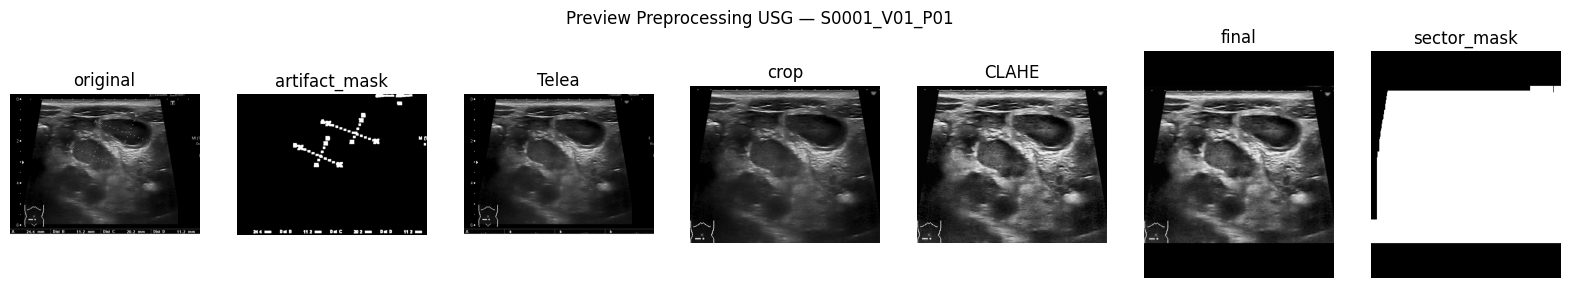

Preprocessing/cache PM3: 250/1741
Preprocessing/cache PM3: 500/1741
Preprocessing/cache PM3: 750/1741
Preprocessing/cache PM3: 1000/1741
Preprocessing/cache PM3: 1250/1741
Preprocessing/cache PM3: 1500/1741
Total citra tersimpan di cache: 1741


In [5]:
BUILD_CACHE = True  # Set True untuk membangun cache citra USG di Proposed Model 3/cache/
us_cfg = USConfig()

sample_row = manifest.iloc[0]
img, msk, stages = preprocess_ultrasound(ROOT / "US_Pictures_clean" / sample_row["path"], us_cfg, return_stages=True)
fig, axes = plt.subplots(1, len(stages), figsize=(20, 3.2))
for ax, (name, arr) in zip(axes, stages.items()):
    ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")
plt.suptitle(f"Preview Preprocessing USG — {sample_row['image_id']}")
plt.show()

if BUILD_CACHE:
    image_cache = build_image_cache(manifest, ROOT / "US_Pictures_clean", us_cfg, PM3_DIR / "cache")
    print("Total citra tersimpan di cache:", len(image_cache))